# Q3: ผู้โดยสารระหว่างประเทศ ขาเข้า vs ขาออก
**กลุ่ม:** Loading Brain... 1%

**คำถาม:** จำนวนผู้โดยสารระหว่างประเทศขาเข้าและขาออกมีความแตกต่างกันอย่างไร จำแนกตามรูปแบบการเดินทาง เปรียบเทียบรายเดือน และวิเคราะห์ความผันผวนภายในปี

**ขอบเขต**
- ปี 2568 (2025) เท่านั้น เพราะต้องครบ 12 เดือนจึงวัดความผันผวนภายในปีได้
- ใช้เฉพาะ 14 บริการที่ระบุขาเข้า/ขาออก (7 คู่) หน่วยคนทั้งหมด จัดเป็น 4 รูปแบบ: ทางอากาศ (4 ท่าอากาศยาน), ทางน้ำ, ทางราง, ทางถนน
- ไม่ใช้ยอดท่าอากาศยานที่ไม่ระบุทิศทาง เพราะเป็นการเดินทางระหว่างจังหวัด คนละนิยามกับระหว่างประเทศ
- ยอดของรูปแบบ = ผลรวมค่าเฉลี่ยต่อวันของแต่ละบริการ (วิธีเดียวกับ Q1)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
plt.rcParams["font.family"] = "Tahoma"     # แสดงภาษาไทยในกราฟ

# โหลดข้อมูลที่เตรียมแล้วจาก 01 และแปลงวันที่กลับเป็น datetime
df = pd.read_csv("../outputs/prepared_daily.csv")
df["date"] = pd.to_datetime(df["date"], format= "%Y-%m-%d")
print("ขนาด: ", df.shape)

from pathlib import Path

# โฟลเดอร์เก็บรูป (สร้างให้ถ้ายังไม่มี)
FIG_DIR = Path("../outputs/figures")
FIG_DIR.mkdir(parents= True, exist_ok= True)

ขนาด:  (18705, 18)


## เตรียมข้อมูล Q3: เลือกบริการและตรวจหน่วย/นิยาม

In [2]:
# เลือกข้อมูลและตรวจหน่วย/นิยาม
# ปี 2025 และเฉพาะบริการที่ระบุขาเข้า/ขาออก
df_q3 = df[(df["year"] == 2025) & (df["direction"] != "ไม่ระบุ")].copy()
print("ขนาด: ", df_q3.shape, "| บริการ: ", df_q3["ยานพาหนะ/ท่า"].nunique(), "| หน่วย: ", df_q3["หน่วย"].unique())

# ทุกรูปแบบต้องมีขาเข้าและขาออกจำนวนบริการเท่ากัน (จับคู่ได้)
display(df_q3.groupby(["รูปแบบการเดินทาง", "direction"])["ยานพาหนะ/ท่า"].nunique())

modes = ["ทางอากาศ", "ทางน้ำ", "ทางราง", "ทางถนน"]

ขนาด:  (5110, 18) | บริการ:  14 | หน่วย:  <StringArray>
['คน']
Length: 1, dtype: str


รูปแบบการเดินทาง  direction
ทางถนน            ขาออก        1
                  ขาเข้า       1
ทางน้ำ            ขาออก        1
                  ขาเข้า       1
ทางราง            ขาออก        1
                  ขาเข้า       1
ทางอากาศ          ขาออก        4
                  ขาเข้า       4
Name: ยานพาหนะ/ท่า, dtype: int64

In [3]:
# ตรวจค่าว่างและค่าศูนย์
qc = df_q3.groupby(["รูปแบบการเดินทาง", "ยานพาหนะ/ท่า"], as_index= False).agg(
    days= ("qty", "count"), zero= ("zero_unconfirmed", "sum"))
qc["missing"] = 365 - qc["days"]
display(qc[(qc["missing"] > 0) | (qc["zero"] > 0)])

,รูปแบบการเดินทาง,ยานพาหนะ/ท่า,days,zero,missing
0,ทางถนน,รถ บขส. ขาออกประเทศ,356,0,9
1,ทางถนน,รถ บขส. ขาเข้าประเทศ,359,0,6
3,ทางน้ำ,ท่าเรือด่านชายแดน ขาเข้าประเทศ,364,0,1
4,ทางราง,รถไฟ ขาออกประเทศ,365,5,0
5,ทางราง,รถไฟ ขาเข้าประเทศ,365,5,0
9,ทางอากาศ,ท่าอากาศยานภูมิภาค ขาเข้าประเทศ,365,1,0


## 3.1 ขาเข้า vs ขาออก รายเดือน แยกรูปแบบ (รูปที่ 1)

In [4]:
# เปรียบเทียบรายเดือน แยกรูปแบบ
# ค่าเฉลี่ยต่อวันของแต่ละบริการในแต่ละเดือน แล้วรวมเป็นยอดของรูปแบบ
svc_m = df_q3.groupby(["รูปแบบการเดินทาง", "ยานพาหนะ/ท่า", "direction", "month"], as_index= False).agg(
    avg_daily= ("qty", "mean"))
monthly = svc_m.groupby(["รูปแบบการเดินทาง", "direction", "month"], as_index= False).agg(
    avg_daily= ("avg_daily", "sum"))
print("ขนาด: ", monthly.shape)

ขนาด:  (96, 4)


In [5]:
# ทั้งปี
# ค่าเฉลี่ยต่อวันทั้งปี แยกรูปแบบและทิศทาง
svc_y = df_q3.groupby(["รูปแบบการเดินทาง", "ยานพาหนะ/ท่า", "direction"], as_index= False).agg(avg_daily= ("qty", "mean"))
annual = svc_y.groupby(["รูปแบบการเดินทาง", "direction"], as_index= False).agg(avg_daily= ("avg_daily", "sum"))

# จับคู่ขาเข้า/ขาออกให้อยู่แถวเดียวกัน
a_in = annual[annual["direction"] == "ขาเข้า"][["รูปแบบการเดินทาง", "avg_daily"]]
a_out = annual[annual["direction"] == "ขาออก"][["รูปแบบการเดินทาง", "avg_daily"]]
yr = pd.merge(a_in, a_out, on= "รูปแบบการเดินทาง", how= "inner", validate= "one_to_one")
yr = yr.rename(columns= {"avg_daily_x": "avg_in", "avg_daily_y": "avg_out"})
yr["net_flow"] = yr["avg_in"] - yr["avg_out"]
yr["in_out_ratio"] = yr["avg_in"] / yr["avg_out"]
display(yr.round(3))

,รูปแบบการเดินทาง,avg_in,avg_out,net_flow,in_out_ratio
0,ทางถนน,563.426,1265.963,-702.537,0.445
1,ทางน้ำ,2200.896,2154.562,46.334,1.022
2,ทางราง,325.548,319.463,6.085,1.019
3,ทางอากาศ,105615.819,94702.184,10913.636,1.115


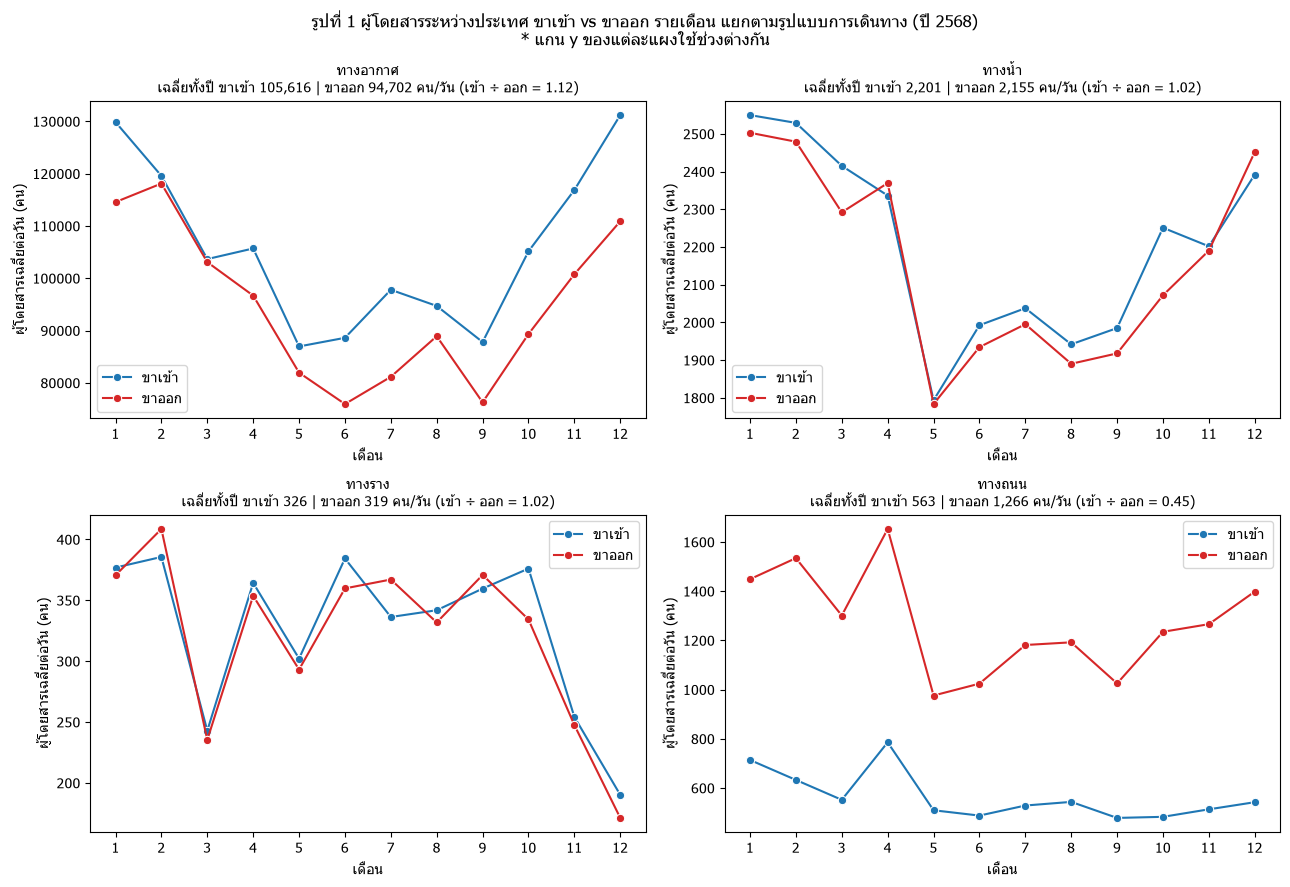

In [6]:
plt.figure(figsize= (13, 9))
for k, mo in enumerate(modes):
    plt.subplot(2, 2, k + 1)
    g = monthly[monthly["รูปแบบการเดินทาง"] == mo]
    sns.lineplot(data= g, x= "month", y= "avg_daily", hue= "direction", hue_order= ["ขาเข้า", "ขาออก"],
                 palette= ["C0", "C3"], marker= "o")                 # ขาเข้าน้ำเงิน ขาออกแดง
    r = yr[yr["รูปแบบการเดินทาง"] == mo].iloc[0]
    plt.title(f"{mo}\nเฉลี่ยทั้งปี ขาเข้า {r['avg_in']:,.0f} | ขาออก {r['avg_out']:,.0f} คน/วัน (เข้า ÷ ออก = {r['in_out_ratio']:.2f})", fontsize= 10)
    plt.xticks(range(1, 13))
    plt.xlabel("เดือน")
    plt.ylabel("ผู้โดยสารเฉลี่ยต่อวัน (คน)")
    plt.ticklabel_format(style= "plain", axis= "y")
    plt.legend(title= "")
plt.suptitle("รูปที่ 1 ผู้โดยสารระหว่างประเทศ ขาเข้า vs ขาออก รายเดือน แยกตามรูปแบบการเดินทาง (ปี 2568)\n* แกน y ของแต่ละแผงใช้ช่วงต่างกัน")
plt.tight_layout()
plt.savefig(FIG_DIR / "q3_fig1_in_out_monthly.png", dpi= 150, bbox_inches= "tight")   # บันทึกรูป
plt.show()

**วิธีอ่าน:** เส้นน้ำเงิน = ขาเข้า, เส้นแดง = ขาออก หัวแต่ละแผงบอกค่าเฉลี่ยทั้งปีและอัตราส่วน ขาเข้า ÷ ขาออก แกน y แต่ละแผงไม่เท่ากัน เพราะทางอากาศใหญ่กว่ารูปแบบอื่นประมาณ 50–300 เท่า

**ผล:**
- **ทางอากาศ (รูปแบบหลัก):** ขาเข้า 105,616 vs ขาออก 94,702 คน/วัน **ขาเข้ามากกว่า 11.5%** สองเส้นต่ำสุดช่วง พ.ค.–ก.ย. แล้วขึ้นสูงสุดช่วง ธ.ค.–ก.พ.
- **ทางน้ำ และทางราง:** สองเส้นเกือบทับกันทั้งปี (เข้า ÷ ออก ประมาณ 1.02)
- **ทางถนน (รถ บขส.):** ขาออก 1,266 vs ขาเข้า 563 คน/วัน **ขาออกมากกว่าเกิน 2 เท่า ทุกเดือน**

## 3.2 อัตราส่วน ขาเข้า ÷ ขาออก รายเดือน (รูปที่ 2)

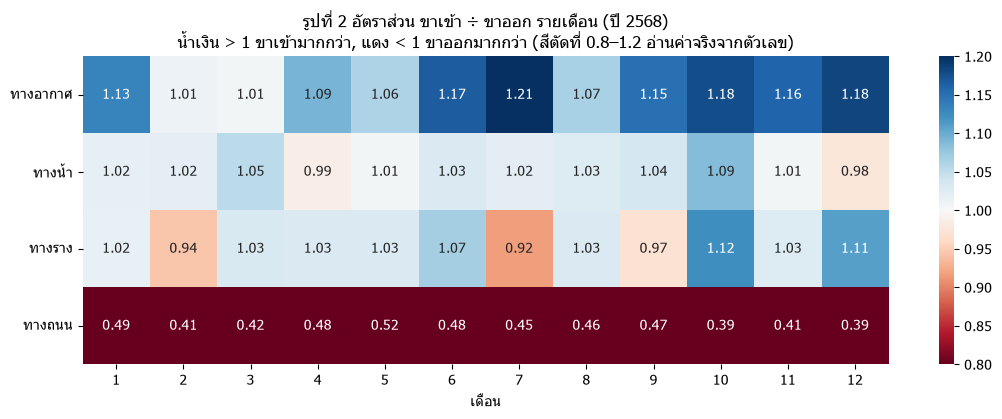

ทางอากาศ | เดือนที่ขาเข้ามากกว่า: 12 | ต่ำสุด: 1.01 | สูงสุด: 1.21
ทางน้ำ | เดือนที่ขาเข้ามากกว่า: 10 | ต่ำสุด: 0.98 | สูงสุด: 1.09
ทางราง | เดือนที่ขาเข้ามากกว่า: 9 | ต่ำสุด: 0.92 | สูงสุด: 1.12
ทางถนน | เดือนที่ขาเข้ามากกว่า: 0 | ต่ำสุด: 0.39 | สูงสุด: 0.52


In [7]:
# จับคู่ขาเข้า/ขาออกรายเดือน
m_in = monthly[monthly["direction"] == "ขาเข้า"][["รูปแบบการเดินทาง", "month", "avg_daily"]]
m_out = monthly[monthly["direction"] == "ขาออก"][["รูปแบบการเดินทาง", "month", "avg_daily"]]
mr = pd.merge(m_in, m_out, on= ["รูปแบบการเดินทาง", "month"], how= "inner", validate= "one_to_one")
mr = mr.rename(columns= {"avg_daily_x": "avg_in", "avg_daily_y": "avg_out"})
mr["net_flow"] = mr["avg_in"] - mr["avg_out"]
mr["in_out_ratio"] = mr["avg_in"] / mr["avg_out"]

# ตาราง รูปแบบ × เดือน สำหรับ heatmap
heat = mr.pivot_table(index= "รูปแบบการเดินทาง", columns= "month", values= "in_out_ratio").loc[modes]

plt.figure(figsize= (13, 4))
sns.heatmap(heat, cmap= "RdBu", center= 1, vmin= 0.8, vmax= 1.2, annot= True, fmt= ".2f")
plt.title("รูปที่ 2 อัตราส่วน ขาเข้า ÷ ขาออก รายเดือน (ปี 2568)\n"
          "น้ำเงิน > 1 ขาเข้ามากกว่า, แดง < 1 ขาออกมากกว่า (สีตัดที่ 0.8–1.2 อ่านค่าจริงจากตัวเลข)")
plt.xlabel("เดือน")
plt.ylabel("")
plt.yticks(rotation= 0)
plt.savefig(FIG_DIR / "q3_fig2_in_out_ratio_heatmap.png", dpi= 150, bbox_inches= "tight")   # บันทึกรูป
plt.show()

for mo in modes:
    g = mr[mr["รูปแบบการเดินทาง"] == mo]
    print(mo, "| เดือนที่ขาเข้ามากกว่า:", (g["in_out_ratio"] > 1).sum(),
          "| ต่ำสุด:", g["in_out_ratio"].min().round(2), "| สูงสุด:", g["in_out_ratio"].max().round(2))

**วิธีอ่าน:** แต่ละช่อง = ขาเข้า ÷ ขาออก ของเดือนนั้น (1.00 = เท่ากัน)

**ผล:**
- **ทางอากาศ ขาเข้ามากกว่าทั้ง 12 เดือน** แต่ขนาดเปลี่ยนตามช่วง: ก.พ.–มี.ค. แทบเท่ากัน (1.01) ส่วน มิ.ย.–ก.ค. และ ก.ย.–ธ.ค. ขาเข้ามากกว่า 15–21% (สูงสุด ก.ค. 1.21) ยกเว้น ส.ค. 1.07
- **ทางน้ำและทางราง** อยู่รอบ 1 สลับขึ้นลง (0.92–1.12) ไม่มีทิศทางชัด
- **ทางถนน ขาออกมากกว่าทุกเดือน** 0.39–0.52 ไม่มีเดือนไหนเข้าใกล้ 1

## 3.3 ความผันผวนภายในปี

monthly_index = เฉลี่ยต่อวันของเดือน ÷ เฉลี่ยต่อวันทั้งปี (1 = เดือนปกติ) แล้ววัดความผันผวนด้วยส่วนเบี่ยงเบนมาตรฐานของ monthly_index 12 เดือน (AIE314 บทที่ 2 หน้า 27)
หารด้วยค่าเฉลี่ยทั้งปีก่อน เพื่อให้รูปแบบที่ขนาดต่างกันมาก (ทางอากาศประมาณ 100,000 vs ทางรางประมาณ 300 คน/วัน) เทียบกันได้

ตัวอย่างคิดมือ: ทางราง ขาออก ธ.ค. = 171.29 ÷ 319.46 = 0.536 (ต่ำกว่าเดือนปกติ 46%)

In [8]:
# ใส่ค่าเฉลี่ยทั้งปีกลับเข้าตารางรายเดือน แล้วคำนวณ monthly_index
monthly = pd.merge(monthly, annual.rename(columns= {"avg_daily": "avg_year"}),
                   on= ["รูปแบบการเดินทาง", "direction"], how= "left", validate= "many_to_one")
monthly["monthly_index"] = monthly["avg_daily"] / monthly["avg_year"]

# ความผันผวน = std ของ monthly_index และช่วง (สูงสุด − ต่ำสุด)
vol = monthly.groupby(["รูปแบบการเดินทาง", "direction"], as_index= False).agg(
    volatility= ("monthly_index", "std"), idx_min= ("monthly_index", "min"), idx_max= ("monthly_index", "max"))
vol["idx_range"] = vol["idx_max"] - vol["idx_min"]
display(vol.round(3))

# เดือนต่ำสุด / สูงสุด ของแต่ละรูปแบบและทิศทาง
for (mo, d), g in monthly.groupby(["รูปแบบการเดินทาง", "direction"]):
    g = g.sort_values("monthly_index")
    print(mo, d, "| ต่ำสุด: เดือน", g["month"].iloc[0], "=", round(g["monthly_index"].iloc[0], 3),
          "| สูงสุด: เดือน", g["month"].iloc[-1], "=", round(g["monthly_index"].iloc[-1], 3))

,รูปแบบการเดินทาง,direction,volatility,idx_min,idx_max,idx_range
0,ทางถนน,ขาออก,0.166,0.771,1.306,0.535
1,ทางถนน,ขาเข้า,0.172,0.849,1.395,0.545
2,ทางน้ำ,ขาออก,0.119,0.828,1.162,0.334
3,ทางน้ำ,ขาเข้า,0.113,0.815,1.159,0.344
4,ทางราง,ขาออก,0.218,0.536,1.279,0.743
5,ทางราง,ขาเข้า,0.199,0.584,1.184,0.600
6,ทางอากาศ,ขาออก,0.156,0.802,1.247,0.445
7,ทางอากาศ,ขาเข้า,0.148,0.823,1.242,0.419


ทางถนน ขาออก | ต่ำสุด: เดือน 5 = 0.771 | สูงสุด: เดือน 4 = 1.306
ทางถนน ขาเข้า | ต่ำสุด: เดือน 9 = 0.849 | สูงสุด: เดือน 4 = 1.395
ทางน้ำ ขาออก | ต่ำสุด: เดือน 5 = 0.828 | สูงสุด: เดือน 1 = 1.162
ทางน้ำ ขาเข้า | ต่ำสุด: เดือน 5 = 0.815 | สูงสุด: เดือน 1 = 1.159
ทางราง ขาออก | ต่ำสุด: เดือน 12 = 0.536 | สูงสุด: เดือน 2 = 1.279
ทางราง ขาเข้า | ต่ำสุด: เดือน 12 = 0.584 | สูงสุด: เดือน 2 = 1.184
ทางอากาศ ขาออก | ต่ำสุด: เดือน 6 = 0.802 | สูงสุด: เดือน 2 = 1.247
ทางอากาศ ขาเข้า | ต่ำสุด: เดือน 5 = 0.823 | สูงสุด: เดือน 12 = 1.242


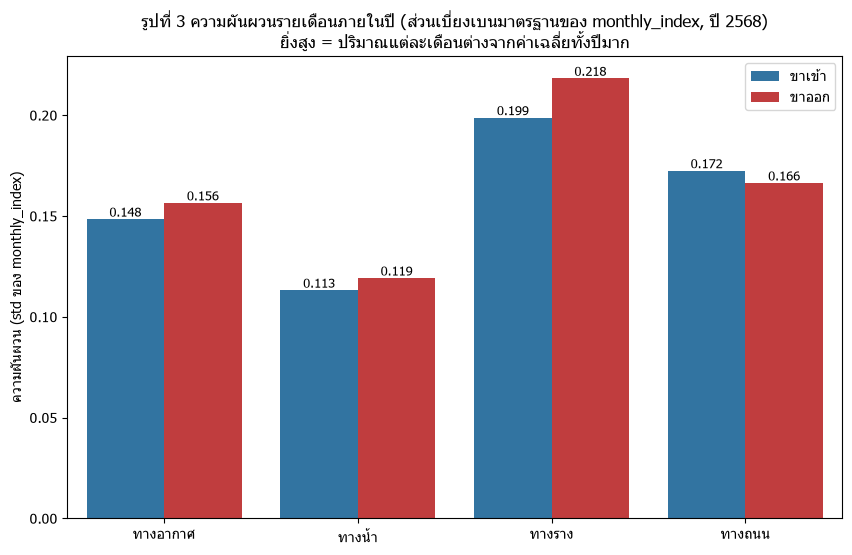

In [9]:
plt.figure(figsize= (10, 6))
ax = sns.barplot(data= vol, x= "รูปแบบการเดินทาง", y= "volatility", hue= "direction", order= modes,
                 hue_order= ["ขาเข้า", "ขาออก"], palette= ["C0", "C3"])
for c in ax.containers:
    ax.bar_label(c, fmt= "{:.3f}", fontsize= 9)
plt.title("รูปที่ 3 ความผันผวนรายเดือนภายในปี (ส่วนเบี่ยงเบนมาตรฐานของ monthly_index, ปี 2568)\n"
          "ยิ่งสูง = ปริมาณแต่ละเดือนต่างจากค่าเฉลี่ยทั้งปีมาก")
plt.xlabel("")
plt.ylabel("ความผันผวน (std ของ monthly_index)")
plt.legend(title= "")
plt.savefig(FIG_DIR / "q3_fig3_volatility.png", dpi= 150, bbox_inches= "tight")   # บันทึกรูป
plt.show()

**ผล:**
- **ทางรางผันผวนมากที่สุด** (ขาออก 0.218, ขาเข้า 0.199) ต่ำสุด ธ.ค. เหลือ 0.54–0.58 ของเดือนปกติ สูงสุด ก.พ. 1.18–1.28
- **ทางน้ำผันผวนน้อยที่สุด** (0.113–0.119) ทั้งสองทิศทางต่ำสุดใน พ.ค.
- **ทางอากาศ** อยู่กลาง ๆ (0.148–0.156) ต่ำช่วง พ.ค.–มิ.ย. และสูงช่วง ธ.ค.–ก.พ.
- ขาเข้าและขาออกของทางอากาศ ทางน้ำ ทางถนน ต่างกันไม่เกิน 0.01 ส่วนทางรางขาออกผันผวนกว่าขาเข้า (0.218 vs 0.199)

In [10]:
# รถไฟมีค่า 0 ที่ยังยืนยันไม่ได้ 5 วัน ทั้งขาเข้าและขาออกในวันเดียวกัน (31 มี.ค., 30–31 พ.ค., 20–21 ต.ค.)
chk = df_q3.copy()
chk.loc[chk["zero_unconfirmed"] == 1, "qty"] = np.nan
c_m = chk.groupby(["รูปแบบการเดินทาง", "ยานพาหนะ/ท่า", "direction", "month"], as_index= False).agg(avg_daily= ("qty", "mean"))
c_m = c_m.groupby(["รูปแบบการเดินทาง", "direction", "month"], as_index= False).agg(avg_daily= ("avg_daily", "sum"))
c_v = c_m.groupby(["รูปแบบการเดินทาง", "direction"])["avg_daily"].agg(["mean", "std"])
c_v["volatility"] = c_v["std"] / c_v["mean"]
display(c_v["volatility"].round(3))

รูปแบบการเดินทาง  direction
ทางถนน            ขาออก        0.166
                  ขาเข้า       0.172
ทางน้ำ            ขาออก        0.119
                  ขาเข้า       0.113
ทางราง            ขาออก        0.213
                  ขาเข้า       0.198
ทางอากาศ          ขาออก        0.156
                  ขาเข้า       0.148
Name: volatility, dtype: float64

**ผล:** ถ้าถือค่า 0 ที่ยังยืนยันไม่ได้ของรถไฟเป็นค่าว่าง ความผันผวนทางราง ขาออกเปลี่ยนจาก 0.218 เป็น 0.213 ค่าอื่นไม่เปลี่ยน ลำดับความผันผวนเหมือนเดิม ข้อสรุป Q3 จึงไม่ขึ้นกับวิธีจัดการค่า 0

## สรุปคำตอบ Q3

1. **ขาเข้า vs ขาออก ตามรูปแบบ (รูปที่ 1):** ทางอากาศขาเข้ามากกว่าขาออก 11.5% (105,616 vs 94,702 คน/วัน) ทางน้ำและทางรางเกือบสมดุล (ประมาณ 1.02) ส่วนทางถนนขาออกมากกว่าขาเข้าเกิน 2 เท่า (1,266 vs 563 คน/วัน)
2. **รายเดือน (รูปที่ 2):** ทางอากาศขาเข้ามากกว่าทั้ง 12 เดือน ช่องว่างกว้างสุด มิ.ย.–ก.ค. และ ก.ย.–ธ.ค. (1.15–1.21, ยกเว้น ส.ค. 1.07) และแคบสุด ก.พ.–มี.ค. (1.01) ทางถนนขาออกมากกว่าทุกเดือน ทางน้ำ/รางสลับไปมารอบ 1
3. **ความผันผวน (รูปที่ 3):** ทางรางผันผวนสูงสุด (0.20–0.22, ต่ำสุด ธ.ค.) ทางน้ำต่ำสุด (0.11–0.12) ทางอากาศกลาง ๆ (0.15) ขาเข้า/ขาออกของรูปแบบเดียวกันผันผวนใกล้เคียงกัน

**ข้อจำกัด:** ข้อมูลไม่บอกสัญชาติหรือเหตุผลการเดินทาง จึงอธิบายสาเหตุไม่ได้ / ทางถนนต่างกันเกิน 2 เท่าทุกเดือน ซึ่งอาจมาจากวิธีนับของแต่ละฝั่งที่ต่างกัน ข้อมูลไม่มีรายละเอียดให้ยืนยัน / ทางราง ทางน้ำ ทางถนน มีฝั่งละ 1 บริการ ฐานเล็ก ตัวเลขแกว่งง่าย / รถไฟมีค่า 0 ที่ยังยืนยันไม่ได้ 5 วัน (ทดสอบแล้วไม่เปลี่ยนข้อสรุป)

## บันทึกผลลัพธ์ Q3
ตารางรูปแบบการเดินทาง × เดือน (4 × 12 = 48 แถว): ขาเข้า/ขาออก, net_flow, in_out_ratio และ monthly_index ทั้งสองทิศทาง ใช้สร้างรูปที่ 1–3 (std ของ monthly_index = ความผันผวนในรูปที่ 3)

In [11]:
# monthly_index แยกขาเข้า/ขาออก ให้อยู่แถวเดียวกัน
idx_in = monthly[monthly["direction"] == "ขาเข้า"][["รูปแบบการเดินทาง", "month", "monthly_index"]]
idx_out = monthly[monthly["direction"] == "ขาออก"][["รูปแบบการเดินทาง", "month", "monthly_index"]]
idx = pd.merge(idx_in, idx_out, on= ["รูปแบบการเดินทาง", "month"], how= "inner", validate= "one_to_one",
               suffixes= ("_in", "_out"))

# รวมกับตารางขาเข้า/ขาออกรายเดือน (mr จากรูปที่ 2)
q3_out = pd.merge(mr, idx, on= ["รูปแบบการเดินทาง", "month"], how= "inner", validate= "one_to_one")
q3_out = q3_out.sort_values(["รูปแบบการเดินทาง", "month"]).reset_index(drop= True)
q3_out.to_csv("../outputs/q3_in_out_monthly.csv", index= False, encoding= "utf-8-sig")

# อ่านกลับมาตรวจ: std ของ monthly_index ต้องเท่ากับความผันผวนในรูปที่ 3
back = pd.read_csv("../outputs/q3_in_out_monthly.csv")
print("บันทึกแล้ว: ", back.shape)
display(back.groupby("รูปแบบการเดินทาง")[["monthly_index_in", "monthly_index_out"]].std().round(3))

บันทึกแล้ว:  (48, 8)


,monthly_index_in,monthly_index_out
รูปแบบการเดินทาง,,
ทางถนน,0.172,0.166
ทางน้ำ,0.113,0.119
ทางราง,0.199,0.218
ทางอากาศ,0.148,0.156
